# Лабораторная работа: многокритериальный выбор технологического решения
## Методы ПАТТЕРН, анализ иерархий (Саати) и решающих матриц (Поспелов)

**Предметная область (тема диплома):** мультиплатформенная интеллектуальная система персональных заметок и напоминаний на основе LLM-агента и RAG. Пользователь управляет заметками и напоминаниями на естественном языке (текст и голос), агент определяет намерение, сохраняет данные, находит их по смыслу и вовремя уведомляет.

**Цель работы:** освоить методы многокритериального экспертного оценивания (ПАТТЕРН, МАИ, метод решающих матриц) и применить их к выбору решений для этой системы.

**Распределение по частям**

| Часть | Метод | Что оцениваем |
|---|---|---|
| 1 | ПАТТЕРН | важность трёх задач системы: A — понимание намерений (LLM-агент), B — поиск по смыслу (RAG), C — напоминания и уведомления |
| 2 | МАИ Саати | выбор способа использования LLM в агенте: A — облачный API, B — открытая модель на собственном сервере, C — компактная модель на устройстве |
| 3 | Решающие матрицы | пересчёт приоритетов «цели → функции → компоненты → исследования» |

**Важно:** все веса и оценки — экспертные (оценки автора). Они заданы в ячейках кода явно, чтобы их можно было заменить на свои и пересчитать результат.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

def fmt_check(name, value, target=1.0, tol=1e-9):
    ok = abs(value - target) < tol
    print(f"{name:<40s} = {value:.6f}   {'OK' if ok else 'ОШИБКА'}")

# Часть 1. Методика ПАТТЕРН

## 1.1. Дерево целей

Общая цель: **создать мультиплатформенную систему заметок и напоминаний, управляемую на естественном языке.**

Задачи (элементы второго уровня):
* **A** — понимание намерений пользователя (LLM-агент, текст и голос);
* **B** — поиск заметок по смыслу (RAG);
* **C** — напоминания и своевременные уведомления.

## 1.2. Критерии и матрица соответствия

Оценка относительной важности задач выполняется по двум критериям:
* **K1** — вклад в удобство для пользователя (естественный диалог, быстрый доступ к нужной записи);
* **K2** — вклад в надёжность системы (не потерять запись, не пропустить напоминание).

$q_x$ — вес критерия (сумма 1), $s_{jx}$ — доля задачи $j$ по критерию $x$ (по каждому критерию сумма по задачам 1), $r_j=\sum_x q_x s_{jx}$.

In [ ]:
tasks = ["A", "B", "C"]
q = np.array([0.60, 0.40])                 # веса критериев K1, K2
S = np.array([[0.50, 0.30, 0.20],          # K1: доли задач A, B, C
              [0.15, 0.30, 0.55]])         # K2: доли задач A, B, C

print("Веса критериев q и матрица соответствия s_jx:")
print(pd.DataFrame(np.column_stack([q, S]), index=["K1", "K2"], columns=["q_x", "A", "B", "C"]))

r = q @ S                                  # r_j = sum_x q_x * s_jx
print("\nИтоговые коэффициенты относительной важности:")
for t, v in zip(tasks, r):
    print(f"  r_{t} = " + " + ".join(f"{q[x]:.2f}*{S[x, tasks.index(t)]:.2f}" for x in range(2)) + f" = {v:.4f}")
order = [tasks[i] for i in np.argsort(-r)]
print("Порядок задач по важности:", " > ".join(order))

print("\n1.4. Проверка условий нормирования:")
fmt_check("sum q_x", q.sum())
for x in range(2):
    fmt_check(f"sum_j s_j{x+1} (критерий K{x+1})", S[x].sum())
fmt_check("sum r_j", r.sum())

Веса критериев q и матрица соответствия s_jx:
      q_x      A      B      C
K1 0.6000 0.5000 0.3000 0.2000
K2 0.4000 0.1500 0.3000 0.5500

Итоговые коэффициенты относительной важности:
  r_A = 0.60*0.50 + 0.40*0.15 = 0.3600
  r_B = 0.60*0.30 + 0.40*0.30 = 0.3000
  r_C = 0.60*0.20 + 0.40*0.55 = 0.3400
Порядок задач по важности: A > C > B

1.4. Проверка условий нормирования:
sum q_x                                  = 1.000000   OK
sum_j s_j1 (критерий K1)                 = 1.000000   OK
sum_j s_j2 (критерий K2)                 = 1.000000   OK
sum r_j                                  = 1.000000   OK


## 1.5. Диаграмма дерева целей с весами

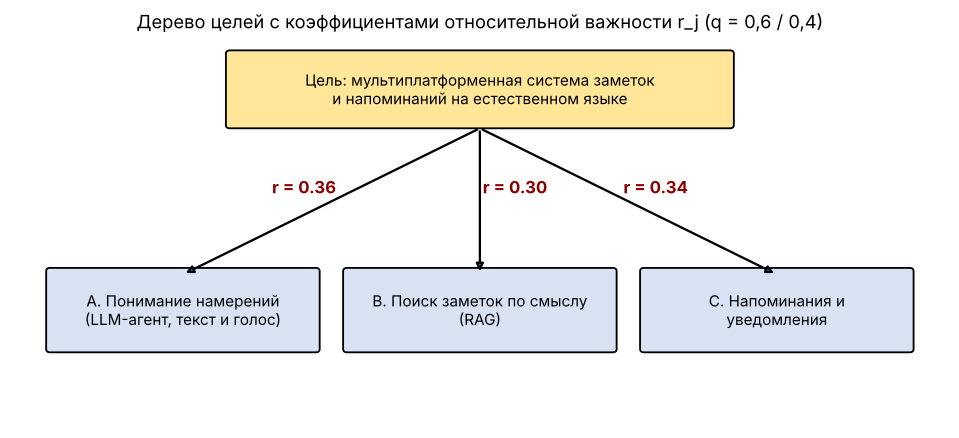

In [ ]:
def box(ax, xy, text, w=3.2, h=1.0, fc="#D9E2F3"):
    p = FancyBboxPatch((xy[0]-w/2, xy[1]-h/2), w, h, boxstyle="round,pad=0.05", fc=fc, ec="black", lw=1.2)
    ax.add_patch(p); ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=10)

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 12); ax.set_ylim(0, 6); ax.axis("off")
box(ax, (6, 5.2), "Цель: мультиплатформенная система заметок\nи напоминаний на естественном языке", w=6.4, h=1.1, fc="#FFE699")
labels = {"A": "A. Понимание намерений\n(LLM-агент, текст и голос)",
          "B": "B. Поиск заметок по смыслу\n(RAG)",
          "C": "C. Напоминания и\nуведомления"}
xs = [2.2, 6, 9.8]
for x, t, rv in zip(xs, tasks, r):
    ax.annotate("", xy=(x, 2.35), xytext=(6, 4.6), arrowprops=dict(arrowstyle="-|>", lw=1.5))
    ax.text((x + 6) / 2 + (0.35 if x > 6 else -0.35 if x < 6 else 0.45), 3.6, f"r = {rv:.2f}", fontsize=11, color="darkred", fontweight="bold", ha="center")
    box(ax, (x, 1.8), labels[t], w=3.4, h=1.2)
ax.set_title("Дерево целей с коэффициентами относительной важности r_j (q = 0,6 / 0,4)", fontsize=12)
plt.show()

## 1.6. Изменится ли порядок задач при равных весах критериев (0,5 / 0,5)?

In [ ]:
q_eq = np.array([0.5, 0.5])
r_eq = q_eq @ S
print("Расчёт при q = (0,50; 0,50):")
for t, v in zip(tasks, r_eq):
    j = tasks.index(t)
    print(f"  r_{t} = 0,50*{S[0, j]:.2f} + 0,50*{S[1, j]:.2f} = {v:.4f}")
fmt_check("sum r_j (равные веса)", r_eq.sum())
print("\nПорядок при весах 0,6/0,4:", " > ".join(order))
print("Порядок при весах 0,5/0,5:", " > ".join(tasks[i] for i in np.argsort(-r_eq)))

Расчёт при q = (0,50; 0,50):
  r_A = 0,50*0.50 + 0,50*0.15 = 0.3250
  r_B = 0,50*0.30 + 0,50*0.30 = 0.3000
  r_C = 0,50*0.20 + 0,50*0.55 = 0.3750
sum r_j (равные веса)                    = 1.000000   OK

Порядок при весах 0,6/0,4: A > C > B
Порядок при весах 0,5/0,5: C > A > B


## 1.7. Взаимная полезность и состояние–срок

**Взаимная полезность** (шкала 0–3: 0 — не помогают, 3 — ключевое значение). Элемент матрицы $M_{ij}$ показывает, насколько разработка $i$ помогает разработке $j$.

In [ ]:
M = pd.DataFrame([[0, 3, 3],
                  [2, 0, 1],
                  [1, 0, 0]], index=tasks, columns=tasks)
print("Матрица взаимной полезности M[i, j]: i помогает j (строка → столбец)")
print(M.to_string())
print("\nСумма по строке (сколько помогает другим):", {k: int(v) for k, v in M.sum(axis=1).items()})
print("Сумма по столбцу (сколько получает помощи):", {k: int(v) for k, v in M.sum(axis=0).items()})

state = pd.DataFrame({
    "Текущее состояние": ["прототип агента: создание заметок и напоминаний", "векторное хранилище и эмбеддинги подключены", "серверный планировщик, базовые уведомления"],
    "Готовность, %": [60, 50, 40],
    "Что осталось": ["голосовые команды, неоднозначные запросы, оценка качества", "гибридный поиск, учёт времени, оценка качества", "push на всех платформах, повторяющиеся напоминания"],
    "Срок, мес.": [2, 3, 3]}, index=tasks)
print("\nСостояние–срок (условные оценки; заменить на фактические):")
print(state.to_string())

Матрица взаимной полезности M[i, j]: i помогает j (строка → столбец)
   A  B  C
A  0  3  3
B  2  0  1
C  1  0  0

Сумма по строке (сколько помогает другим): {'A': 6, 'B': 3, 'C': 1}
Сумма по столбцу (сколько получает помощи): {'A': 3, 'B': 3, 'C': 4}

Состояние–срок (условные оценки; заменить на фактические):
                                 Текущее состояние  Готовность, %                                               Что осталось  Срок, мес.
A  прототип агента: создание заметок и напоминаний             60  голосовые команды, неоднозначные запросы, оценка качества           2
B      векторное хранилище и эмбеддинги подключены             50             гибридный поиск, учёт времени, оценка качества           3
C       серверный планировщик, базовые уведомления             40         push на всех платформах, повторяющиеся напоминания           3


# Часть 2. Метод анализа иерархий (Саати)

## 2.1. Иерархия

* **Цель:** выбрать способ использования LLM в агенте, обеспечивающий точное понимание команд пользователя при приемлемой стоимости и защите персональных данных.
* **Критерии:** K1 — качество понимания намерений и вызова инструментов; K2 — стоимость эксплуатации (чем дешевле, тем лучше); K3 — приватность данных.
* **Альтернативы:** A — облачный API; B — открытая модель на собственном сервере; C — компактная модель на устройстве пользователя.

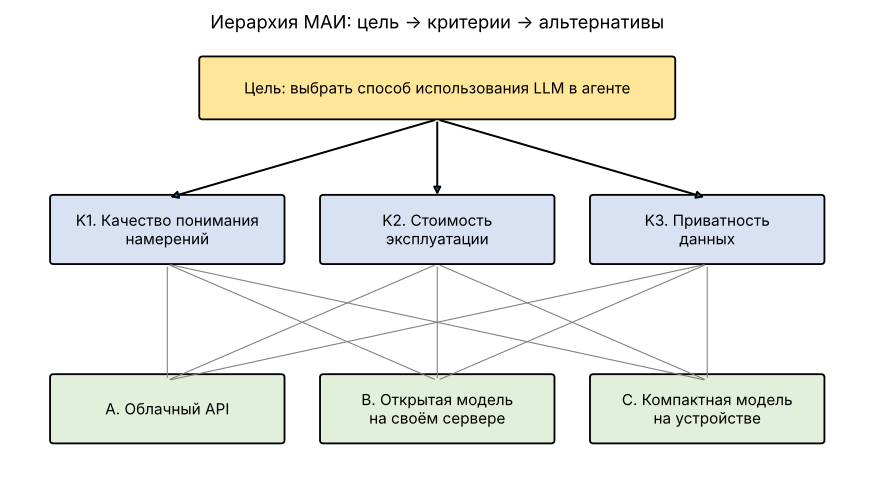

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")
box(ax, (6, 6.2), "Цель: выбрать способ использования LLM в агенте", w=6.6, h=0.9, fc="#FFE699")
crit = ["K1. Качество понимания\nнамерений", "K2. Стоимость\nэксплуатации", "K3. Приватность\nданных"]
alt = ["A. Облачный API", "B. Открытая модель\nна своём сервере", "C. Компактная модель\nна устройстве"]
cx = [2.2, 6, 9.8]
for x, t in zip(cx, crit):
    ax.annotate("", xy=(x, 4.45), xytext=(6, 5.7), arrowprops=dict(arrowstyle="-|>", lw=1.3))
    box(ax, (x, 3.95), t, w=3.2, h=1.0, fc="#D9E2F3")
for x, t in zip(cx, alt):
    for x2 in cx:
        ax.annotate("", xy=(x, 1.55), xytext=(x2, 3.4), arrowprops=dict(arrowstyle="-", lw=0.7, color="gray"))
    box(ax, (x, 1.1), t, w=3.2, h=1.0, fc="#E2EFDA")
ax.set_title("Иерархия МАИ: цель → критерии → альтернативы", fontsize=12)
plt.show()

## 2.2. Матрица парных сравнений критериев

Шкала Саати: 1 — равная важность, 3 — умеренное превосходство, 5 — сильное, 7 — очень сильное, 9 — крайнее, 2/4/6/8 — промежуточные; при обратном предпочтении записывается обратное число. Для персональных заметок качество понимания команд важнее всего, приватность важнее стоимости.

In [ ]:
RI = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12}      # индекс случайной согласованности Саати

def saaty(A):
    # веса через геометрическое среднее строк, lambda_max, CI, CR
    A = np.array(A, float); n = len(A)
    g = np.prod(A, axis=1) ** (1 / n)
    w = g / g.sum()
    lam = np.mean((A @ w) / w)
    CI = (lam - n) / (n - 1)
    CR = CI / RI[n] if RI[n] > 0 else 0.0
    return g, w, lam, CI, CR

def check_reciprocal(A):
    A = np.array(A, float)
    return np.allclose(A * A.T, 1.0)

crit_names = ["K1", "K2", "K3"]
Ak = np.array([[1,   3,   2],
               [1/3, 1,   1/2],
               [1/2, 2,   1]])
print("Матрица парных сравнений критериев (a_ij: во сколько раз i важнее j):")
print(pd.DataFrame(Ak, index=crit_names, columns=crit_names).to_string())
print("Обратная симметричность a_ij * a_ji = 1:", check_reciprocal(Ak))

Матрица парных сравнений критериев (a_ij: во сколько раз i важнее j):
       K1     K2     K3
K1 1.0000 3.0000 2.0000
K2 0.3333 1.0000 0.5000
K3 0.5000 2.0000 1.0000
Обратная симметричность a_ij * a_ji = 1: True


## 2.3. Веса критериев (геометрическое среднее и нормирование) и 2.4. Согласованность

$g_i=\sqrt[n]{\prod_j a_{ij}}$, $w_i=g_i/\sum g_i$; $\lambda_{\max}$ находится как среднее отношений $(Aw)_i/w_i$; $CI=(\lambda_{\max}-n)/(n-1)$; $CR=CI/RI$, где для $n=3$ $RI=0{,}58$. Согласованность приемлема при $CR<0{,}1$.

In [ ]:
gk, wk, lam_k, CI_k, CR_k = saaty(Ak)
tab = pd.DataFrame({"Геометрическое среднее g_i": gk, "Вес w_i": wk}, index=crit_names)
tab.loc["Сумма"] = [gk.sum(), wk.sum()]
print(tab.to_string())
print(f"\nlambda_max = {lam_k:.4f}")
print(f"CI = (lambda_max - n)/(n - 1) = {CI_k:.4f}")
print(f"CR = CI/RI = {CI_k:.4f}/{RI[3]} = {CR_k:.4f}")
print("Согласованность приемлема (CR < 0,1):", CR_k < 0.1)

       Геометрическое среднее g_i  Вес w_i
K1                         1.8171   0.5396
K2                         0.5503   0.1634
K3                         1.0000   0.2970
Сумма                      3.3674   1.0000

lambda_max = 3.0092
CI = (lambda_max - n)/(n - 1) = 0.0046
CR = CI/RI = 0.0046/0.58 = 0.0079
Согласованность приемлема (CR < 0,1): True


## 2.5. Матрицы парных сравнений альтернатив по каждому критерию

* **K1 (качество):** облачные модели заметно сильнее открытых серверных, а те — сильнее компактных.
* **K2 (стоимость, чем дешевле — тем выше приоритет):** компактная модель на устройстве почти бесплатна для разработчика; облачный API при небольшой аудитории дешевле собственного GPU-сервера.
* **K3 (приватность):** данные остаются на устройстве (C) лучше, чем на собственном сервере (B), и намного лучше, чем у стороннего облака (A).

In [ ]:
alts = ["A", "B", "C"]
A_K1 = np.array([[1,   3,   7],
                 [1/3, 1,   2],
                 [1/7, 1/2, 1]])
A_K2 = np.array([[1,   2,   1/3],
                 [1/2, 1,   1/5],
                 [3,   5,   1]])
A_K3 = np.array([[1,   1/4, 1/7],
                 [4,   1,   1/2],
                 [7,   2,   1]])
local = {}
for name, Am in zip(crit_names, [A_K1, A_K2, A_K3]):
    g, w, lam, CI, CR = saaty(Am)
    local[name] = dict(w=w, lam=lam, CI=CI, CR=CR)
    print(f"--- {name} ---")
    print(pd.DataFrame(Am, index=alts, columns=alts).to_string())
    print(f"локальные приоритеты p_i{name}: " + ", ".join(f"{a}={v:.4f}" for a, v in zip(alts, w)))
    print(f"lambda_max = {lam:.4f}, CI = {CI:.4f}, CR = {CR:.4f}  ->  {'согласована' if CR < 0.1 else 'НЕ согласована'}\n")

--- K1 ---
       A      B      C
A 1.0000 3.0000 7.0000
B 0.3333 1.0000 2.0000
C 0.1429 0.5000 1.0000
локальные приоритеты p_iK1: A=0.6817, B=0.2158, C=0.1025
lambda_max = 3.0026, CI = 0.0013, CR = 0.0023  ->  согласована

--- K2 ---
       A      B      C
A 1.0000 2.0000 0.3333
B 0.5000 1.0000 0.2000
C 3.0000 5.0000 1.0000
локальные приоритеты p_iK2: A=0.2297, B=0.1220, C=0.6483
lambda_max = 3.0037, CI = 0.0018, CR = 0.0032  ->  согласована

--- K3 ---
       A      B      C
A 1.0000 0.2500 0.1429
B 4.0000 1.0000 0.5000
C 7.0000 2.0000 1.0000
локальные приоритеты p_iK3: A=0.0823, B=0.3150, C=0.6026
lambda_max = 3.0020, CI = 0.0010, CR = 0.0017  ->  согласована



## 2.6–2.7. Синтез итоговых приоритетов

$P_i=\sum_k w_k\,p_{ik}$ — сумма произведений веса критерия на локальный приоритет альтернативы по этому критерию.

In [ ]:
Pmat = np.column_stack([local[k]["w"] for k in crit_names])   # строки: A,B,C; столбцы: K1,K2,K3
P = Pmat @ wk
tab = pd.DataFrame({"Вес w_k": wk}, index=crit_names)
for i, a in enumerate(alts):
    tab[f"p_{a}"] = Pmat[i]
tab.loc["Итог"] = [np.nan] + list(P)
print(tab.to_string(na_rep=""))
print()
for a, v in zip(alts, P):
    j = alts.index(a)
    print(f"P_{a} = " + " + ".join(f"{wk[k]:.3f}*{Pmat[j, k]:.3f}" for k in range(3)) + f" = {v:.4f}")
fmt_check("sum P", P.sum())
names = {"A": "облачный API", "B": "открытая модель на своём сервере", "C": "компактная модель на устройстве"}
best = alts[int(np.argmax(P))]
print(f"\nПобедитель: {best} — {names[best]} (P = {P.max():.4f})")

      Вес w_k    p_A    p_B    p_C
K1     0.5396 0.6817 0.2158 0.1025
K2     0.1634 0.2297 0.1220 0.6483
K3     0.2970 0.0823 0.3150 0.6026
Итог          0.4298 0.2300 0.3402

P_A = 0.540*0.682 + 0.163*0.230 + 0.297*0.082 = 0.4298
P_B = 0.540*0.216 + 0.163*0.122 + 0.297*0.315 = 0.2300
P_C = 0.540*0.103 + 0.163*0.648 + 0.297*0.603 = 0.3402
sum P                                    = 1.000000   OK

Победитель: A — облачный API (P = 0.4298)


## 2.8. Анализ чувствительности

Меняем веса критериев и смотрим, остаётся ли победитель прежним.

In [ ]:
scenarios = {
    "базовые веса":                     wk,
    "K3 (приватность) самый важный":     np.array([0.20, 0.20, 0.60]),
    "K2 (стоимость) самый важный":       np.array([0.20, 0.60, 0.20]),
    "K1 (качество) самый важный":        np.array([0.70, 0.10, 0.20]),
    "равные веса":                       np.array([1/3, 1/3, 1/3]),
}
rows = []
for name, w in scenarios.items():
    Pw = Pmat @ w
    rows.append([name] + [f"{x:.3f}" for x in w] + [f"{x:.3f}" for x in Pw] + [alts[int(np.argmax(Pw))]])
sens = pd.DataFrame(rows, columns=["Сценарий", "w1", "w2", "w3", "P_A", "P_B", "P_C", "Победитель"])
print(sens.to_string(index=False))

# плавное изменение веса K3 при пропорциональной перенормировке w1, w2
w3_grid = np.linspace(0, 1, 1001)
Psweep = np.zeros((len(w3_grid), 3))
for i, w3 in enumerate(w3_grid):
    rest = (1 - w3) / (wk[0] + wk[1])
    w = np.array([wk[0] * rest, wk[1] * rest, w3])
    Psweep[i] = Pmat @ w
win = np.argmax(Psweep, axis=1)
cross = w3_grid[np.where(np.diff(win) != 0)[0]]
print("\nВес K3, при котором победитель меняется:", ", ".join(f"{c:.3f}" for c in cross) if len(cross) else "не меняется")
print("Победители по участкам:", [alts[k] for k in dict.fromkeys(win)])
print(f"Базовый вес K3 = {wk[2]:.3f}")

                     Сценарий    w1    w2    w3   P_A   P_B   P_C Победитель
                 базовые веса 0.540 0.163 0.297 0.430 0.230 0.340          A
K3 (приватность) самый важный 0.200 0.200 0.600 0.232 0.257 0.512          C
  K2 (стоимость) самый важный 0.200 0.600 0.200 0.291 0.179 0.530          C
   K1 (качество) самый важный 0.700 0.100 0.200 0.517 0.226 0.257          A
                  равные веса 0.333 0.333 0.333 0.331 0.218 0.451          C

Вес K3, при котором победитель меняется: 0.400
Победители по участкам: ['A', 'C']
Базовый вес K3 = 0.297


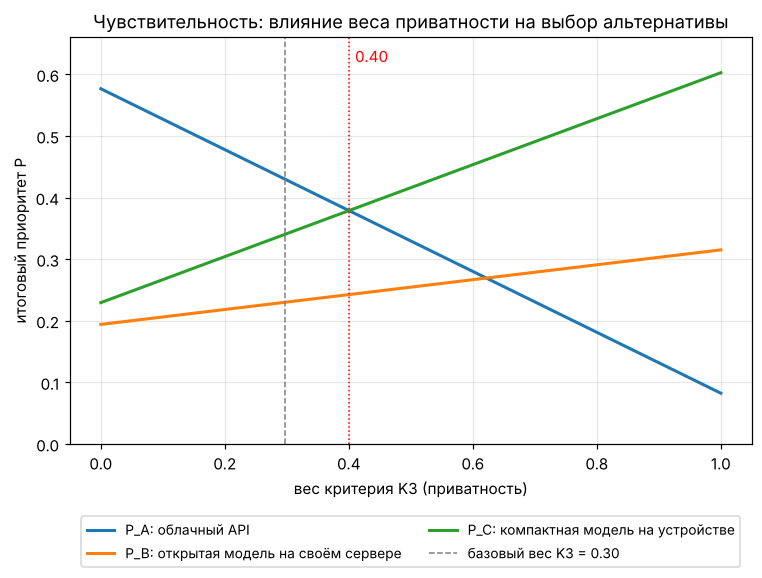

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for i, a in enumerate(alts):
    ax.plot(w3_grid, Psweep[:, i], lw=2, label=f"P_{a}: {names[a]}")
ax.axvline(wk[2], color="gray", ls="--", lw=1, label=f"базовый вес K3 = {wk[2]:.2f}")
for c in cross:
    ax.axvline(c, color="red", ls=":", lw=1)
    ax.text(c + 0.01, 0.62, f"{c:.2f}", color="red", fontsize=10)
ax.set_xlabel("вес критерия K3 (приватность)"); ax.set_ylabel("итоговый приоритет P")
ax.set_title("Чувствительность: влияние веса приватности на выбор альтернативы")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2); ax.grid(alpha=0.3)
ax.set_ylim(0, 0.66)
plt.show()

## 2.9. Ограничения МАИ

* **Зависимость от набора критериев и альтернатив.** Результат определяется тем, какие критерии выбраны и как они сформулированы; пропущенный критерий (например, задержка ответа или поддержка русского языка) может изменить победителя.
* **Рост числа сравнений.** Для $n$ объектов нужно $n(n-1)/2$ сравнений в каждой матрице, при $m$ критериях — ещё $m$ матриц альтернатив; эксперту сложно сохранять согласованность при росте $n$.
* **Проблема обращения рангов.** Добавление или удаление альтернативы (в том числе почти копии уже имеющейся) может изменить порядок остальных альтернатив, потому что приоритеты в МАИ относительны и нормируются на сумму 1.
* **Субъективность и дискретная шкала.** Оценки зависят от эксперта; шкала 1–9 огрубляет суждения; согласованность ($CR<0{,}1$) не гарантирует правильность мнений, а лишь отсутствие противоречий между ними.

# Часть 3. Метод решающих матриц Г.С. Поспелова

## 3.1. Четырёхуровневая схема

| Уровень | Элементы |
|---|---|
| Цели проекта (направления) | G1 — управление заметками и напоминаниями на естественном языке; G2 — поиск информации по смыслу; G3 — своевременные напоминания |
| Функции системы (разработки) | F1 — распознавание намерений и извлечение данных; F2 — сохранение и структурирование заметок; F3 — семантический поиск (RAG); F4 — планирование и доставка уведомлений; F5 — голосовой ввод |
| Программные компоненты (прикладные исследования) | K1 — LLM-агент; K2 — векторное хранилище и эмбеддинги; K3 — планировщик и сервис уведомлений; K4 — модуль распознавания речи; K5 — мультиплатформенные клиенты |
| Необходимые исследования (фундаментальные) | R1 — устойчивое извлечение структуры из текста; R2 — векторные представления и гибридный поиск; R3 — надёжная доставка уведомлений в мобильных ОС; R4 — распознавание речи для русского языка; R5 — приватность и безопасность данных при работе с LLM |

## 3.2. Вектор приоритетов направлений p(0)

In [ ]:
G = ["G1", "G2", "G3"]
F = ["F1", "F2", "F3", "F4", "F5"]
K = ["K1", "K2", "K3", "K4", "K5"]
R = ["R1", "R2", "R3", "R4", "R5"]
dir_names = {"G1": "Управление на естеств. языке", "G2": "Поиск по смыслу", "G3": "Своевременные напоминания"}

p0 = np.array([0.40, 0.35, 0.25])
print(pd.DataFrame({"Направление": [dir_names[g] for g in G], "Вес": p0}, index=G).to_string())
fmt_check("sum p(0)", p0.sum())

                     Направление    Вес
G1  Управление на естеств. языке 0.4000
G2               Поиск по смыслу 0.3500
G3     Своевременные напоминания 0.2500
sum p(0)                                 = 1.000000   OK


## 3.3–3.6. Матрицы вкладов и пересчёт $p^{(k)}=B^{(k)}p^{(k-1)}$

В каждом столбце сумма вкладов равна 1: столбец показывает, как «разделяется» вес элемента верхнего уровня между элементами нижнего.

In [ ]:
# B(1): функции x цели (столбцы G1, G2, G3)
B1 = np.array([[0.35, 0.15, 0.25],     # F1 распознавание намерений
               [0.15, 0.20, 0.10],     # F2 сохранение заметок
               [0.05, 0.60, 0.00],     # F3 семантический поиск
               [0.10, 0.00, 0.60],     # F4 планирование и доставка уведомлений
               [0.35, 0.05, 0.05]])    # F5 голосовой ввод
# B(2): компоненты x функции (столбцы F1..F5)
B2 = np.array([[0.70, 0.20, 0.25, 0.10, 0.05],   # K1 LLM-агент
               [0.05, 0.40, 0.65, 0.00, 0.00],   # K2 векторное хранилище
               [0.00, 0.05, 0.00, 0.65, 0.00],   # K3 планировщик
               [0.10, 0.00, 0.00, 0.00, 0.75],   # K4 распознавание речи
               [0.15, 0.35, 0.10, 0.25, 0.20]])  # K5 клиенты
# B(3): исследования x компоненты (столбцы K1..K5)
B3 = np.array([[0.50, 0.05, 0.10, 0.05, 0.05],   # R1 извлечение структуры из текста
               [0.10, 0.75, 0.00, 0.00, 0.05],   # R2 векторные представления и поиск
               [0.00, 0.00, 0.80, 0.00, 0.45],   # R3 доставка уведомлений
               [0.00, 0.00, 0.00, 0.85, 0.15],   # R4 распознавание речи
               [0.40, 0.20, 0.10, 0.10, 0.30]])  # R5 приватность и безопасность

for name, B, rows, cols in [("B(1)", B1, F, G), ("B(2)", B2, K, F), ("B(3)", B3, R, K)]:
    print(f"{name}  (строки — {rows[0]}..{rows[-1]}, столбцы — {cols[0]}..{cols[-1]})")
    print(pd.DataFrame(B, index=rows, columns=cols).to_string())
    print("суммы по столбцам:", B.sum(axis=0), "\n")

p1 = B1 @ p0
p2 = B2 @ p1
p3 = B3 @ p2
print("p(1) = B(1) p(0):", {n: round(float(v), 4) for n, v in zip(F, p1)})
print("p(2) = B(2) p(1):", {n: round(float(v), 4) for n, v in zip(K, p2)})
print("p(3) = B(3) p(2):", {n: round(float(v), 4) for n, v in zip(R, p3)})
print("\n3.6. Проверка нормирования на каждом уровне:")
for k, p in enumerate([p0, p1, p2, p3]):
    fmt_check(f"sum p({k})", p.sum())

B(1)  (строки — F1..F5, столбцы — G1..G3)
       G1     G2     G3
F1 0.3500 0.1500 0.2500
F2 0.1500 0.2000 0.1000
F3 0.0500 0.6000 0.0000
F4 0.1000 0.0000 0.6000
F5 0.3500 0.0500 0.0500
суммы по столбцам: [1. 1. 1.] 

B(2)  (строки — K1..K5, столбцы — F1..F5)
       F1     F2     F3     F4     F5
K1 0.7000 0.2000 0.2500 0.1000 0.0500
K2 0.0500 0.4000 0.6500 0.0000 0.0000
K3 0.0000 0.0500 0.0000 0.6500 0.0000
K4 0.1000 0.0000 0.0000 0.0000 0.7500
K5 0.1500 0.3500 0.1000 0.2500 0.2000
суммы по столбцам: [1. 1. 1. 1. 1.] 

B(3)  (строки — R1..R5, столбцы — K1..K5)
       K1     K2     K3     K4     K5
R1 0.5000 0.0500 0.1000 0.0500 0.0500
R2 0.1000 0.7500 0.0000 0.0000 0.0500
R3 0.0000 0.0000 0.8000 0.0000 0.4500
R4 0.0000 0.0000 0.0000 0.8500 0.1500
R5 0.4000 0.2000 0.1000 0.1000 0.3000
суммы по столбцам: [1. 1. 1. 1. 1.] 

p(1) = B(1) p(0): {'F1': 0.255, 'F2': 0.155, 'F3': 0.23, 'F4': 0.19, 'F5': 0.17}
p(2) = B(2) p(1): {'K1': 0.2945, 'K2': 0.2243, 'K3': 0.1313, 'K4': 0.153, 'K5': 0.197

## 3.7. Итоговая таблица и схема

In [ ]:
fund = {"R1": "Устойчивое извлечение структуры из текста", "R2": "Векторные представления и гибридный поиск",
        "R3": "Надёжная доставка уведомлений в мобильных ОС", "R4": "Распознавание речи (русский язык)",
        "R5": "Приватность и безопасность данных с LLM"}
comp = {"K1": "LLM-агент", "K2": "Векторное хранилище и эмбеддинги", "K3": "Планировщик и уведомления",
        "K4": "Распознавание речи", "K5": "Мультиплатформенные клиенты"}
func = {"F1": "Распознавание намерений", "F2": "Сохранение заметок", "F3": "Семантический поиск (RAG)",
        "F4": "Планирование и доставка уведомлений", "F5": "Голосовой ввод"}

def vec(names, p): return "; ".join(f"{n} {v:.3f}" for n, v in zip(names, p))
final = pd.DataFrame({"Уровень": ["Направления", "Разработки (функции)", "Прикладные исследования (компоненты)", "Фундаментальные исследования"],
                      "Вектор приоритетов": [vec(G, p0), vec(F, p1), vec(K, p2), vec(R, p3)]})
print(final.to_string(index=False))

top = int(np.argmax(p3))
print(f"\nНаибольший итоговый вес: {R[top]} — {fund[R[top]]} ({p3[top]:.4f})")
print("Ранжирование фундаментальных исследований:")
for i in np.argsort(-p3):
    print(f"  {R[i]}  {p3[i]:.4f}  {fund[R[i]]}")

print(f"\nОткуда берётся вес {R[top]}: p3[{R[top]}] = sum_k B3[{R[top]}, k] * p2[k]")
for k_, (bk, pk) in enumerate(zip(B3[top], p2)):
    print(f"  {K[k_]} ({comp[K[k_]]}): {bk:.2f} * {pk:.4f} = {bk * pk:.4f}")
print(f"  сумма = {float(B3[top] @ p2):.4f}")

                             Уровень                               Вектор приоритетов
                         Направления                     G1 0.400; G2 0.350; G3 0.250
                Разработки (функции) F1 0.255; F2 0.155; F3 0.230; F4 0.190; F5 0.170
Прикладные исследования (компоненты) K1 0.294; K2 0.224; K3 0.131; K4 0.153; K5 0.197
        Фундаментальные исследования R1 0.189; R2 0.207; R3 0.194; R4 0.160; R5 0.250

Наибольший итоговый вес: R5 — Приватность и безопасность данных с LLM (0.2502)
Ранжирование фундаментальных исследований:
  R5  0.2502  Приватность и безопасность данных с LLM
  R2  0.2075  Векторные представления и гибридный поиск
  R3  0.1937  Надёжная доставка уведомлений в мобильных ОС
  R1  0.1891  Устойчивое извлечение структуры из текста
  R4  0.1596  Распознавание речи (русский язык)

Откуда берётся вес R5: p3[R5] = sum_k B3[R5, k] * p2[k]
  K1 (LLM-агент): 0.40 * 0.2945 = 0.1178
  K2 (Векторное хранилище и эмбеддинги): 0.20 * 0.2243 = 0.0449
  K3 (Планир

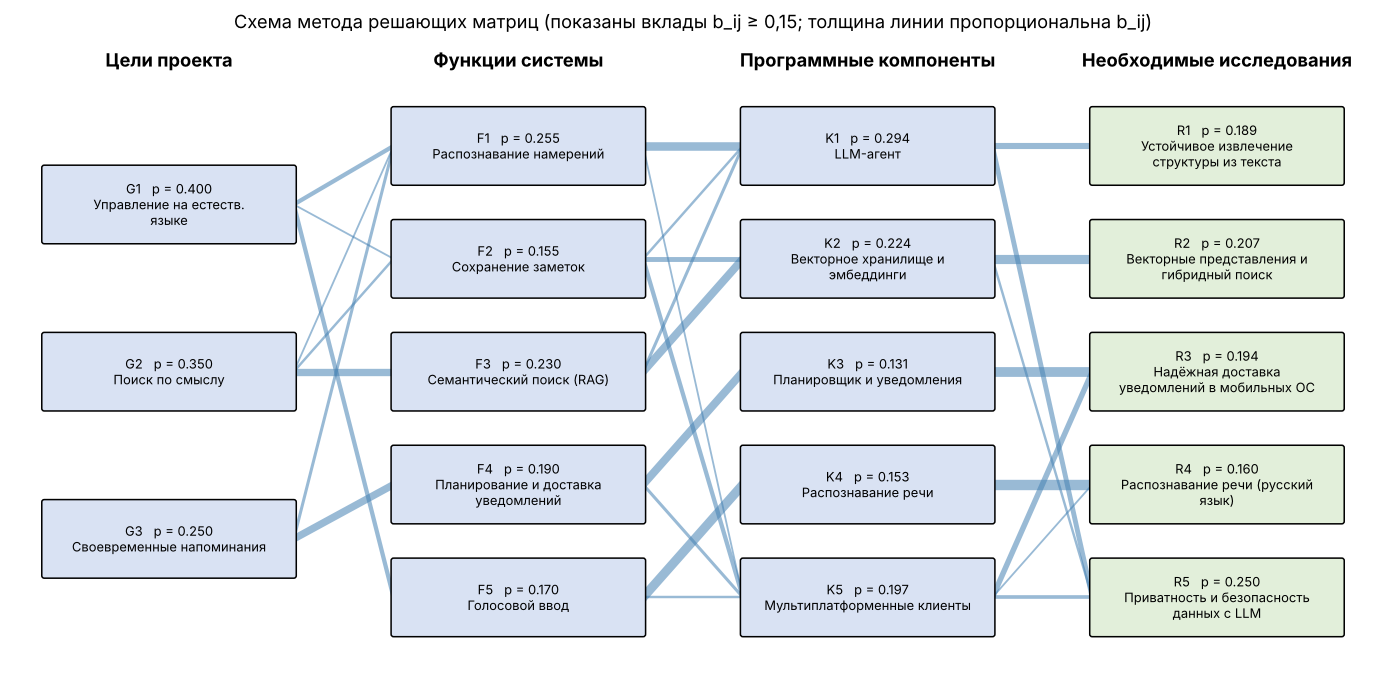

In [ ]:
import textwrap
levels = [("Цели проекта", G, p0, [dir_names[g] for g in G], None),
          ("Функции системы", F, p1, [func[f] for f in F], B1),
          ("Программные компоненты", K, p2, [comp[k] for k in K], B2),
          ("Необходимые исследования", R, p3, [fund[r_] for r_ in R], B3)]
fig, ax = plt.subplots(figsize=(16, 7.6))
ax.axis("off"); ax.set_xlim(0, 16.4); ax.set_ylim(-0.3, 7.4)
xs = [1.9, 6.1, 10.3, 14.5]; bw = 3.0                      # центры колонок и ширина блоков
pos = []
for xi, (title, ids, p, nm, B) in zip(xs, levels):
    n = len(ids); ys = np.linspace(6.1, 0.7, n) if n > 3 else np.array([5.4, 3.4, 1.4])
    pos.append(ys); ax.text(xi, 7.05, title, ha="center", fontsize=12, fontweight="bold")
for li in range(1, 4):                                     # линии только для вкладов b_ij >= 0,15
    B = levels[li][4]
    for i in range(B.shape[0]):
        for j in range(B.shape[1]):
            if B[i, j] >= 0.15:
                ax.plot([xs[li-1] + bw/2, xs[li] - bw/2], [pos[li-1][j], pos[li][i]], color="steelblue", lw=B[i, j] * 8, alpha=0.55, zorder=1)
for li, (title, ids, p, nm, B) in enumerate(levels):
    for i, (idn, pv, name) in enumerate(zip(ids, p, nm)):
        txt = f"{idn}   p = {pv:.3f}\n" + textwrap.fill(name, 27)
        ax.add_patch(FancyBboxPatch((xs[li] - bw/2, pos[li][i] - 0.44), bw, 0.88, boxstyle="round,pad=0.03",
                                    fc="#E2EFDA" if li == 3 else "#D9E2F3", ec="black", lw=1, zorder=3))
        ax.text(xs[li], pos[li][i], txt, ha="center", va="center", fontsize=8.5, zorder=4)
ax.set_title("Схема метода решающих матриц (показаны вклады b_ij ≥ 0,15; толщина линии пропорциональна b_ij)", fontsize=12)
plt.show()

# Часть 4. Сравнительный анализ методов

| Критерий сравнения | ПАТТЕРН | МАИ Саати | Метод решающих матриц |
|---|---|---|---|
| Основной вопрос | Какие задачи (элементы дерева целей) важнее для вышестоящей цели | Какая из альтернатив лучше по набору критериев | Какие работы и исследования нужно вести, чтобы достичь целей проекта |
| Тип матриц | «элементы × критерии» (доли по каждому критерию) | квадратные матрицы парных сравнений | матрицы вкладов «нижний уровень × верхний уровень» |
| Проверка согласованности | нормировка сумм (Σq = 1, Σs = 1, Σr = 1) | индекс и отношение согласованности (CI, CR < 0,1) | нормировка столбцов (Σ вкладов = 1) |
| Число уровней | 2–3 (цель → задачи) | 3 и более (цель → критерии → альтернативы) | 4 (цели → функции → компоненты → исследования) |
| Когда применять | структурирование проблемы, расстановка приоритетов задач | выбор одного варианта из нескольких по нескольким критериям | планирование программы разработок и исследований, распределение ресурсов |

In [ ]:
print("Сводка результатов:")
print(f"Часть 1 (ПАТТЕРН): r = " + ", ".join(f"{t}={v:.2f}" for t, v in zip(tasks, r)) + f"; порядок {' > '.join(order)}; при равных весах {' > '.join(tasks[i] for i in np.argsort(-r_eq))}")
print(f"Часть 2 (МАИ): веса критериев = " + ", ".join(f"{c}={v:.3f}" for c, v in zip(crit_names, wk)) + f"; CR = {CR_k:.3f}; P = " + ", ".join(f"{a}={v:.3f}" for a, v in zip(alts, P)) + f"; победитель {best}")
print(f"Часть 3 (Поспелов): наибольший вес у {R[top]} = {p3[top]:.3f}")

Сводка результатов:
Часть 1 (ПАТТЕРН): r = A=0.36, B=0.30, C=0.34; порядок A > C > B; при равных весах C > A > B
Часть 2 (МАИ): веса критериев = K1=0.540, K2=0.163, K3=0.297; CR = 0.008; P = A=0.430, B=0.230, C=0.340; победитель A
Часть 3 (Поспелов): наибольший вес у R5 = 0.250


## Выводы

* **ПАТТЕРН:** наибольшую относительную важность получила задача A (понимание намерений агентом): r_A = 0.36; затем C (напоминания): 0.34; затем B (поиск): 0.30. При равных весах критериев порядок меняется на C > A > B: первой становится C (r_C = 0.375), то есть порядок зависит от соотношения «удобство/надёжность», заданного экспертом.
* **МАИ:** в базовой постановке лучшим способом использования LLM оказался облачный API (A): P_A = 0.430, против 0.340 у компактной модели на устройстве (C) и 0.230 у открытой серверной модели (B). Все матрицы согласованы (наибольшее CR = 0.008 < 0,1). Анализ чувствительности показал, что при весе приватности выше 0.40 лидером становится C, а при равных весах критериев и при сильном приоритете стоимости победителем также оказывается C, то есть выбор неустойчив к изменению весов критериев.
* **Решающие матрицы:** по цепочке «цели → функции → компоненты → исследования» наибольший итоговый вес у фундаментальной работы R5 — Приватность и безопасность данных с LLM (0.250); далее R2 (0.207) и R3 (0.194). Работа R5 лидирует потому, что вносит вклад сразу в несколько самых «тяжёлых» компонентов: LLM-агент, мультиплатформенные клиенты и векторное хранилище.
* **Сравнение методов:** для выбора конкретного технологического решения (LLM) подходит МАИ, для приоритизации задач проекта — ПАТТЕРН, для планирования программы исследований под цели дипломного проекта — метод решающих матриц. Методы дополняют друг друга.